# PHYS 2550 Homework 2 — Parts 2 and 3
This notebook produces every number and figure of Part 2 (data and preprocessing) and Part 3 (FCNN vs. CNN). It runs on Google Colab or locally.
Rule used throughout: after the split in 2.1, **only the training set is used for statistics and decisions**; the test set is only used for the final evaluation of trained models in Part 3.

In [1]:
import os, json, urllib.request
import numpy as np, h5py
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED = 42
rng = np.random.default_rng(SEED)
FIG_DIR = "figs"; os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10})

def find_data():
    for p in ["Galaxy10.h5", "/content/Galaxy10.h5", "/content/drive/MyDrive/Galaxy10.h5"]:
        if os.path.exists(p):
            return p
    url = "https://www.astro.utoronto.ca/~bovy/Galaxy10/Galaxy10.h5"   # link from the astroNN docs
    urllib.request.urlretrieve(url, "Galaxy10.h5")
    return "Galaxy10.h5"

with h5py.File(find_data(), "r") as f:
    images = f["images"][:]          # (N, 69, 69, 3) uint8
    labels = f["ans"][:].astype(int)

CLASS_NAMES = ["Disk, face-on, no spiral", "Smooth, completely round", "Smooth, in-between round",
               "Smooth, cigar shaped", "Disk, edge-on, rounded bulge", "Disk, edge-on, boxy bulge",
               "Disk, edge-on, no bulge", "Disk, face-on, tight spiral", "Disk, face-on, medium spiral",
               "Disk, face-on, loose spiral"]

## 2.1 First look

In [2]:
print("images:", images.shape, images.dtype, "| pixel range:", images.min(), "to", images.max())
print("labels:", labels.shape, labels.dtype, "| classes:", np.unique(labels))
counts = np.bincount(labels, minlength=10)
print(f"\n{'class':>5}  {'morphology':<30}{'count':>7}{'share':>8}")
for c in range(10):
    print(f"{c:>5}  {CLASS_NAMES[c]:<30}{counts[c]:>7}{100*counts[c]/len(labels):>7.2f}%")
print("total:", counts.sum())

images: (21785, 69, 69, 3) uint8 | pixel range: 0 to 255
labels: (21785,) int64 | classes: [0 1 2 3 4 5 6 7 8 9]

class  morphology                      count   share
    0  Disk, face-on, no spiral         3461  15.89%
    1  Smooth, completely round         6997  32.12%
    2  Smooth, in-between round         6292  28.88%
    3  Smooth, cigar shaped              349   1.60%
    4  Disk, edge-on, rounded bulge     1534   7.04%
    5  Disk, edge-on, boxy bulge          17   0.08%
    6  Disk, edge-on, no bulge           589   2.70%
    7  Disk, face-on, tight spiral      1121   5.15%
    8  Disk, face-on, medium spiral      906   4.16%
    9  Disk, face-on, loose spiral       519   2.38%
total: 21785


**Decision on the rarest class.** Class 5 has only 17 images, so it is dropped (nine classes remain, labels re-numbered 0–8). The reason is given in the text of the report: with 17 images a 70/15/15 split leaves 2–3 images each in validation and test, which is too few for any metric of that class to mean anything.

In [3]:
KEEP = [0, 1, 2, 3, 4, 6, 7, 8, 9]                       # class 5 dropped
label_map = {old: new for new, old in enumerate(KEEP)}
names9 = [CLASS_NAMES[c] for c in KEEP]
SHORT = ["face-on\nno spiral", "round", "in-between", "cigar", "edge-on\nrounded bulge",
         "edge-on\nno bulge", "tight\nspiral", "medium\nspiral", "loose\nspiral"]

idx_all = np.where(np.isin(labels, KEEP))[0]
y_all = np.array([label_map[l] for l in labels[idx_all]])

# stratified 70 / 15 / 15 split with a fixed seed (indices refer to the original arrays)
idx_tr, idx_tmp, y_tr, y_tmp = train_test_split(idx_all, y_all, test_size=0.30, stratify=y_all, random_state=SEED)
idx_va, idx_te, y_va, y_te = train_test_split(idx_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
np.savez("splits.npz", idx_train=idx_tr, idx_val=idx_va, idx_test=idx_te, keep=np.array(KEEP))
print("train / val / test sizes:", len(idx_tr), len(idx_va), len(idx_te))
print(f"\n{'class':>5}{'train':>8}{'val':>7}{'test':>7}   share in each split (%)")
for c in range(9):
    n = [np.sum(y == c) for y in (y_tr, y_va, y_te)]
    print(f"{c:>5}{n[0]:>8}{n[1]:>7}{n[2]:>7}   " + "  ".join(f"{100*k/len(y):.2f}" for k, y in zip(n, (y_tr, y_va, y_te))))

# from here on the test set is not used (until the final evaluations in Part 3)
Xtr = images[idx_tr]          # uint8 (N,69,69,3)
Xva = images[idx_va]

train / val / test sizes: 15237 3265 3266

class   train    val   test   share in each split (%)
    0    2423    519    519   15.90  15.90  15.89
    1    4898   1049   1050   32.15  32.13  32.15
    2    4404    944    944   28.90  28.91  28.90
    3     244     53     52   1.60  1.62  1.59
    4    1074    230    230   7.05  7.04  7.04
    5     412     88     89   2.70  2.70  2.73
    6     785    168    168   5.15  5.15  5.14
    7     634    136    136   4.16  4.17  4.16
    8     363     78     78   2.38  2.39  2.39


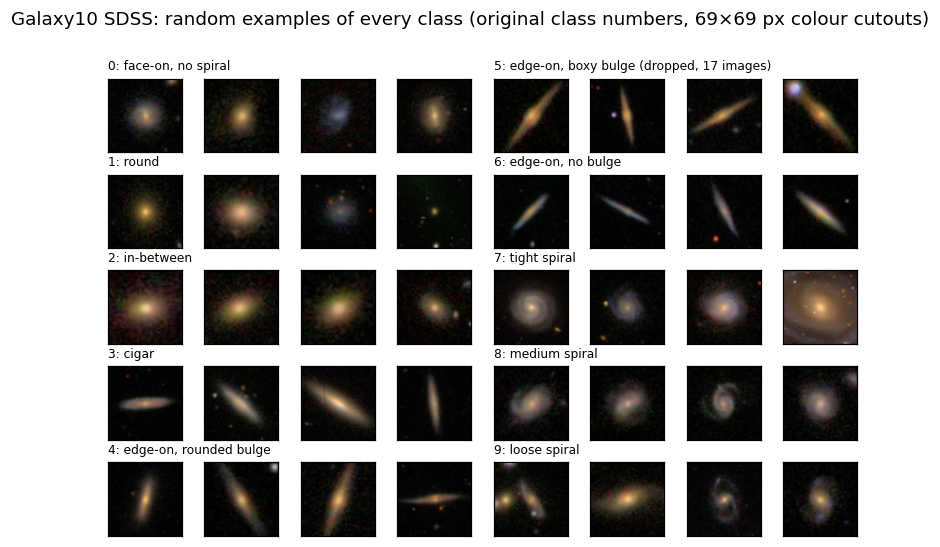

In [4]:
# example grid: 4 random images of every one of the 10 original classes (row labels = original class numbers).
# Kept classes: drawn from the training set. Dropped class 5: drawn from the full data (it belongs to no split).
OLD_SHORT = ["face-on, no spiral", "round", "in-between", "cigar", "edge-on, rounded bulge", "edge-on, boxy bulge",
             "edge-on, no bulge", "tight spiral", "medium spiral", "loose spiral"]
new_of = {old: new for new, old in enumerate(KEEP)}
fig, axes = plt.subplots(5, 8, figsize=(9, 5.4), gridspec_kw=dict(wspace=0.05, hspace=0.3))
for old in range(10):
    if old in new_of:
        pool = np.where(y_tr == new_of[old])[0]; src = Xtr; tag = f"{old}: {OLD_SHORT[old]}"
    else:
        pool = np.where(labels == old)[0]; src = images; tag = f"{old}: {OLD_SHORT[old]} (dropped, 17 images)"
    pick = rng.choice(pool, 4, replace=False)
    for j, i in enumerate(pick):
        ax = axes[old % 5, (old // 5) * 4 + j]; ax.imshow(src[i]); ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_title(tag, loc="left", fontsize=8)
fig.suptitle("Galaxy10 SDSS: random examples of every class (original class numbers, 69×69 px colour cutouts)", y=0.995)
plt.savefig(f"{FIG_DIR}/fig_2_1_grid.png", bbox_inches="tight"); plt.show()

## 2.2 Is the dataset noisy?
### (a) Sky noise from the outer 4-pixel frame
Everything below uses the training images only. σ_sky is estimated twice per image and band: with the standard deviation and with the robust 1.4826 × MAD.

frame pixels: 1040
band  median sky  median σ_std  median σ_MAD   σ_std>1.5σ_MAD
   g         6.0          5.92          4.45            42.3%
   r         6.0          5.16          2.97            38.7%
   i         3.0          4.48          2.97            39.1%


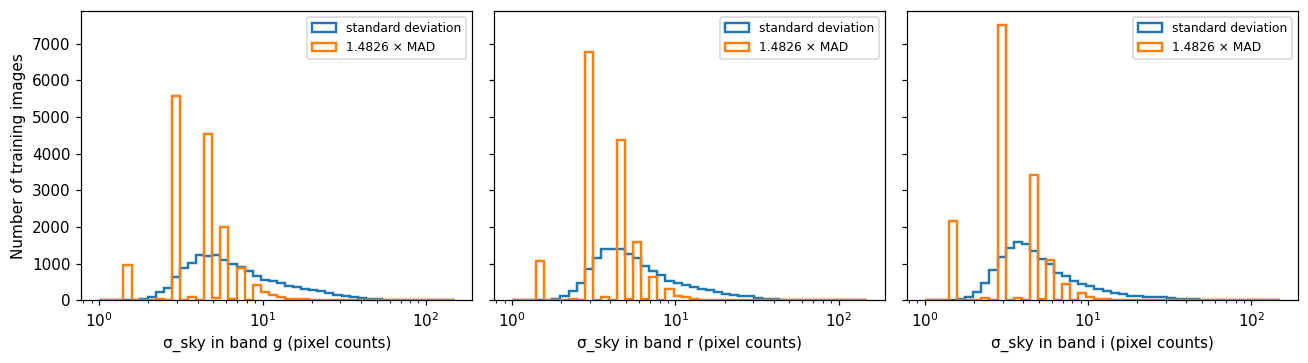

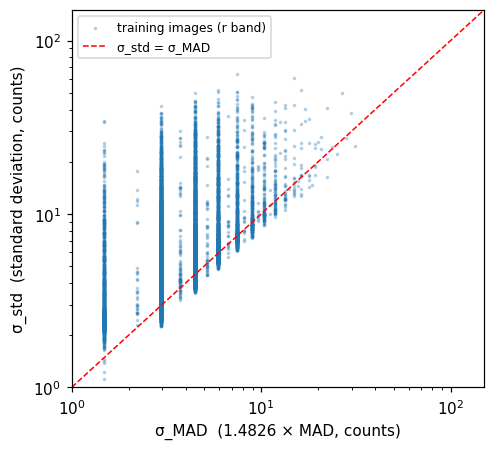

In [5]:
frame = np.ones((69, 69), bool); frame[4:-4, 4:-4] = False          # outer 4-pixel frame, 1040 pixels
B = Xtr[:, frame, :].astype(np.float32)                              # (N, 1040, 3)
sky_med = np.median(B, axis=1)                                       # (N, 3) background level
sky_std = B.std(axis=1)
sky_mad = 1.4826 * np.median(np.abs(B - sky_med[:, None, :]), axis=1)
del B
BANDS = ["g", "r", "i"]
print("frame pixels:", frame.sum())
print(f"{'band':>4} {'median sky':>11} {'median σ_std':>13} {'median σ_MAD':>13} {'σ_std>1.5σ_MAD':>16}")
for b in range(3):
    print(f"{BANDS[b]:>4} {np.median(sky_med[:,b]):>11.1f} {np.median(sky_std[:,b]):>13.2f} {np.median(sky_mad[:,b]):>13.2f} "
          f"{100*np.mean(sky_std[:,b] > 1.5*np.maximum(sky_mad[:,b], 1.4826)):>15.1f}%")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
bins = np.logspace(0, np.log10(150), 45)
for b in range(3):
    axes[b].hist(np.clip(sky_std[:, b], 1, 149), bins, histtype="step", lw=1.6, label="standard deviation")
    axes[b].hist(np.clip(sky_mad[:, b], 1, 149), bins, histtype="step", lw=1.6, label="1.4826 × MAD")
    axes[b].set_xscale("log"); axes[b].set_xlabel(f"σ_sky in band {BANDS[b]} (pixel counts)")
    axes[b].legend(fontsize=8)
axes[0].set_ylabel("Number of training images")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_2_2a_sky_hist.png", bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.scatter(np.maximum(sky_mad[:, 1], 1.4826), sky_std[:, 1], s=2, alpha=0.25, label="training images (r band)")
ax.plot([1, 150], [1, 150], "r--", lw=1, label="σ_std = σ_MAD")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(1, 150); ax.set_ylim(1, 150)
ax.set_xlabel("σ_MAD  (1.4826 × MAD, counts)"); ax.set_ylabel("σ_std  (standard deviation, counts)")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_2_2a_sky_scatter.png", bbox_inches="tight"); plt.show()

### (b) Signal-to-noise ratio per image
SNR = (background-subtracted flux in a circular aperture of radius 8 px at the image centre) / (σ_sky √N_pix), using σ_sky = 1.4826 × MAD (with a floor of one 8-bit step, 1.4826, because the data are integers).

aperture pixels: 197
class name                         median SNR g median SNR r median SNR i  SNR_r<5  SNR_r<20
    0 Disk, face-on, no spiral            499.5        457.3        385.2     0.0%      0.0%
    1 Smooth, completely round            421.0        376.7        277.3     0.0%      0.0%
    2 Smooth, in-between round            431.4        387.0        306.6     0.0%      0.0%
    3 Smooth, cigar shaped                458.4        434.2        436.4     0.0%      0.0%
    4 Disk, edge-on, rounded bulge        479.9        403.2        311.8     0.0%      0.0%
    5 Disk, edge-on, no bulge             411.5        377.0        416.8     0.0%      0.0%
    6 Disk, face-on, tight spiral         597.7        533.9        556.2     0.0%      0.0%
    7 Disk, face-on, medium spiral        540.5        484.2        474.2     0.0%      0.0%
    8 Disk, face-on, loose spiral         432.8        401.4        387.5     0.0%      0.0%
all classes, r band: median 404.4, 10th pct 261.1

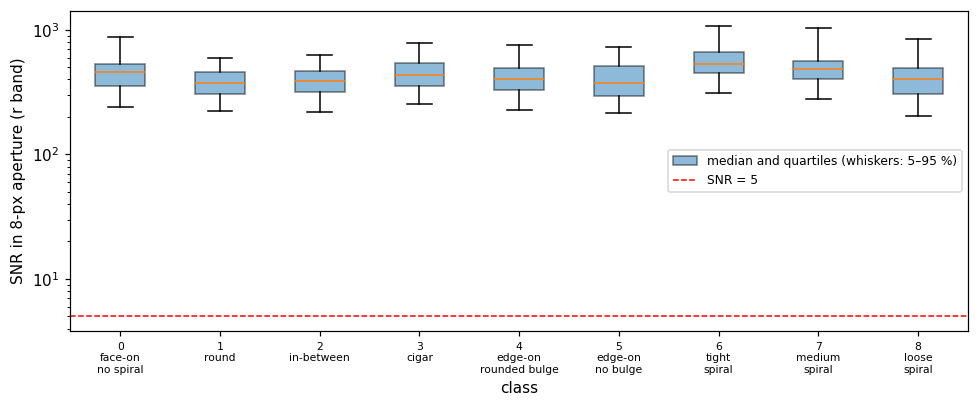

In [6]:
yy, xx = np.mgrid[:69, :69]
rad = np.hypot(yy - 34, xx - 34)
ap = rad <= 8; Npix = int(ap.sum())
sigma_sky = np.maximum(sky_mad, 1.4826)
flux = (Xtr[:, ap, :].astype(np.float32) - sky_med[:, None, :]).sum(axis=1)       # (N,3)
snr = flux / (sigma_sky * np.sqrt(Npix))
print("aperture pixels:", Npix)
print(f"{'class':>5} {'name':<28}" + "".join(f"{'median SNR '+b:>13}" for b in BANDS) + f"{'SNR_r<5':>9}{'SNR_r<20':>10}")
for c in range(9):
    s = snr[y_tr == c]
    print(f"{c:>5} {names9[c]:<28}" + "".join(f"{np.median(s[:,b]):>13.1f}" for b in range(3)) +
          f"{100*np.mean(s[:,1]<5):>8.1f}%{100*np.mean(s[:,1]<20):>9.1f}%")
print("all classes, r band: median %.1f, 10th pct %.1f, 90th pct %.1f" % tuple(np.percentile(snr[:, 1], [50, 10, 90])))

fig, ax = plt.subplots(figsize=(9, 3.8))
data = [np.clip(snr[y_tr == c, 1], 0.3, None) for c in range(9)]
bp = ax.boxplot(data, whis=(5, 95), showfliers=False, patch_artist=True)
for p in bp["boxes"]: p.set_alpha(0.5)
ax.axhline(5, color="r", ls="--", lw=1, label="SNR = 5")
ax.set_yscale("log"); ax.set_xticks(range(1, 10)); ax.set_xticklabels([f"{c}\n{SHORT[c]}" for c in range(9)], fontsize=7)
ax.set_xlabel("class"); ax.set_ylabel("SNR in 8-px aperture (r band)")
ax.legend([bp["boxes"][0], ax.lines[-1]], ["median and quartiles (whiskers: 5–95 %)", "SNR = 5"], fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_2_2b_snr.png", bbox_inches="tight"); plt.show()

### (c) Contamination and digitisation
An image counts as *contaminated* if at least 25 of the 1040 frame pixels (about 2.4 %) lie more than 5 σ_sky above the background in the r band. The table shows how much the result depends on these two choices.

fraction of training images with >= m frame pixels above k σ_sky (r band):
   k / m      10      25      50
       3   88.6%   65.6%   34.6%
       5   47.2%   26.6%   11.6%
      10   23.5%   11.2%    3.8%

chosen definition (k=5, m=25): 26.6% of training images are contaminated
corner pixels (radius > 34 px, inside the frame): 768
   k / m       5      10      25   (corners only)
       3   88.3%   75.6%   44.1%
       5   49.9%   37.3%   17.7%
      10   27.2%   18.3%    7.0%
   contaminated fraction per class (%): [28.4 23.6 21.  34.  44.1 32.  32.4 29.5 42.7]
   mean σ_std/σ_MAD  contaminated: 3.48   clean: 1.25



saturation (value 255): 0.00051% of all pixel values; 2.29% of images have at least one
   per band, share of pixel values at 255: g 0.00070%  r 0.00010%  i 0.00075%
   zero-valued pixels: 2.76% of all pixel values
   saturated pixels per affected image: median 2, max 40


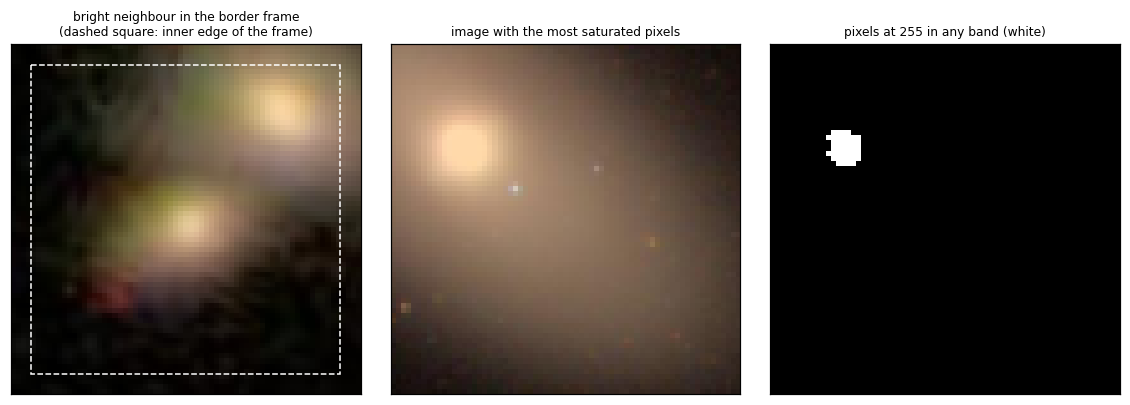

In [7]:
Br = Xtr[:, frame, 1].astype(np.float32)
excess = (Br - sky_med[:, 1:2]) / sigma_sky[:, 1:2]
print("fraction of training images with >= m frame pixels above k σ_sky (r band):")
print(f"{'k / m':>8}" + "".join(f"{m:>8}" for m in (10, 25, 50)))
for k in (3, 5, 10):
    print(f"{k:>8}" + "".join(f"{100*np.mean((excess>k).sum(1) >= m):>7.1f}%" for m in (10, 25, 50)))
contam = (excess > 5).sum(1) >= 25
print(f"\nchosen definition (k=5, m=25): {100*contam.mean():.1f}% of training images are contaminated")
# stricter variant: only the four corners of the frame (radius > 34 px), where the galaxy's own light hardly reaches
corner = frame & (rad > 34); print("corner pixels (radius > 34 px, inside the frame):", int(corner.sum()))
ex_c = (Xtr[:, corner, 1].astype(np.float32) - sky_med[:, 1:2]) / sigma_sky[:, 1:2]
print(f"{'k / m':>8}" + "".join(f"{m:>8}" for m in (5, 10, 25)) + "   (corners only)")
for k in (3, 5, 10):
    print(f"{k:>8}" + "".join(f"{100*np.mean((ex_c>k).sum(1) >= m):>7.1f}%" for m in (5, 10, 25)))
print("   contaminated fraction per class (%):", np.round([100*contam[y_tr == c].mean() for c in range(9)], 1))
print("   mean σ_std/σ_MAD  contaminated: %.2f   clean: %.2f" % ((sky_std[contam,1]/sigma_sky[contam,1]).mean(), (sky_std[~contam,1]/sigma_sky[~contam,1]).mean()))

sat = (Xtr == 255)
print(f"\nsaturation (value 255): {100*sat.mean():.5f}% of all pixel values; {100*sat.reshape(len(Xtr),-1).any(1).mean():.2f}% of images have at least one")
print(f"   per band, share of pixel values at 255: g {100*sat[...,0].mean():.5f}%  r {100*sat[...,1].mean():.5f}%  i {100*sat[...,2].mean():.5f}%")
print(f"   zero-valued pixels: {100*(Xtr==0).mean():.2f}% of all pixel values")
npix_sat = sat.reshape(len(Xtr), -1).sum(1)
print("   saturated pixels per affected image: median %d, max %d" % (np.median(npix_sat[npix_sat>0]), npix_sat.max()))

i_c = np.argmax((excess > 5).sum(1)); i_s = np.argmax(npix_sat)
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6))
axes[0].imshow(Xtr[i_c]); axes[0].add_patch(plt.Rectangle((3.5, 3.5), 61, 61, fill=False, ec="w", lw=1, ls="--"))
axes[0].set_title("bright neighbour in the border frame\n(dashed square: inner edge of the frame)", fontsize=8)
axes[1].imshow(Xtr[i_s]); axes[1].set_title("image with the most saturated pixels", fontsize=8)
axes[2].imshow(sat[i_s].any(axis=2), cmap="gray"); axes[2].set_title("pixels at 255 in any band (white)", fontsize=8)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_2_2c_examples.png", bbox_inches="tight"); plt.show()

## 2.3 Preprocessing pipeline
### (a) Crop size from the average radial light profile

images with a defined R50 / R90: 15237 / 15237 of 15237
half-light radius R50 (px): median 12.0, 10th-90th pct 10.0-14.0
radius where profile drops below 2 sigma_sky (px): median 25.0, 10th-90th pct 21.0-29.0
share of images with that radius <= 24 px: 46.2%
fraction of the r-band flux of the full 69x69 cutout that lies inside a central square crop (training set):
   24x24: 53.6%
   32x32: 71.6%
   40x40: 83.8%
   48x48: 91.4%
   56x56: 96.0%
   64x64: 98.8%
radius containing 90% of the flux (px): median 24.0, 75th pct 25.0, 90th pct 27.0
share of images with R90 <= 24 px (inscribed radius of a 48x48 crop): 62.0%
mean profile in the r band at r = 0, 10, 20, 24, 30: [166.7  66.5  18.1   9.6   3.9]  (median σ_sky = 3.0)


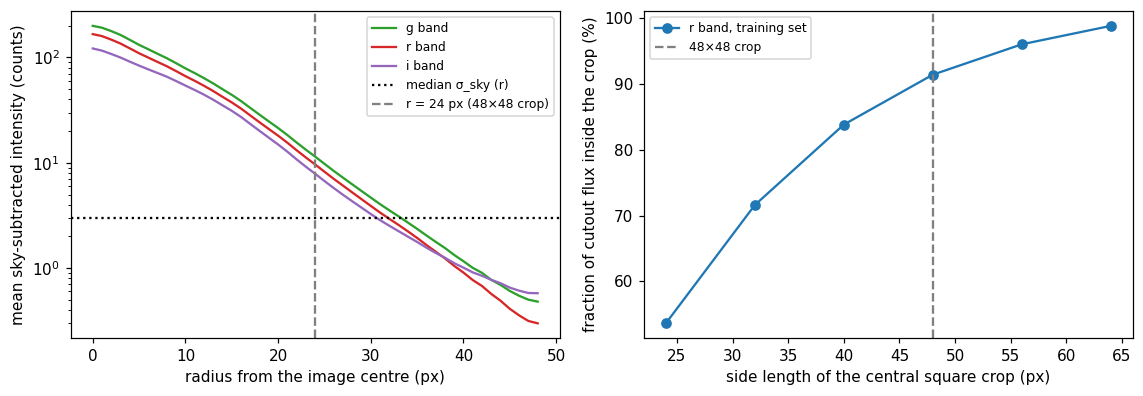

In [8]:
Rbin = np.rint(rad).astype(int); nb = Rbin.max() + 1
onehot = np.zeros((69 * 69, nb), np.float32); onehot[np.arange(69 * 69), Rbin.ravel()] = 1
cnt = onehot.sum(0)

def radial_profiles(X, med):                       # sky-subtracted azimuthal average, (N, nb, 3)
    out = np.empty((len(X), nb, 3), np.float32)
    for s in range(0, len(X), 2000):
        a = X[s:s+2000].astype(np.float32) - med[s:s+2000, None, None, :]
        out[s:s+2000] = np.einsum("npb,pr->nrb", a.reshape(len(a), -1, 3), onehot) / cnt[None, :, None]
    return out

prof = radial_profiles(Xtr, sky_med)
mean_prof = prof.mean(0)                           # (nb, 3)

def crop_flux(size):
    s = (69 - size) // 2; tot = 0.0; full = 0.0
    for a in range(0, len(Xtr), 2000):
        d = Xtr[a:a+2000, :, :, 1].astype(np.float32) - sky_med[a:a+2000, 1, None, None]
        tot += d[:, s:s+size, s:s+size].sum(); full += d.sum()
    return tot / full

sizes = [24, 32, 40, 48, 56, 64]
enc = {s: crop_flux(s) for s in sizes}

# radius containing 90 % of the flux inside r<=34 (largest circle that fits in the cutout), per image, r band
cum = np.cumsum(prof[:, :35, 1] * cnt[None, :35], axis=1)
ok_flux = cum[:, -1] > 0                                           # images whose total flux inside r<=34 is positive
cum = cum / np.where(ok_flux, cum[:, -1], 1.0)[:, None]
def first_radius(frac):                                            # first radius at which the cumulative flux reaches frac
    hit = cum >= frac
    return np.where(ok_flux & hit.any(1), hit.argmax(1), -1)      # -1 = not defined for this image
r90, r50 = first_radius(0.9), first_radius(0.5)
print("images with a defined R50 / R90:", int((r50 >= 0).sum()), "/", int((r90 >= 0).sum()), "of", len(r90))
r90v, r50v = r90[r90 >= 0], r50[r50 >= 0]
# radius where the azimuthal profile (smoothed over 3 px) first drops below 2 sigma_sky: a size that does not depend on the sky offset
ps = np.apply_along_axis(lambda v: np.convolve(v, np.ones(3) / 3, mode="same"), 1, prof[:, :35, 1])
r2s = np.array([np.argmax(p < 2 * s) if (p < 2 * s).any() else 35 for p, s in zip(ps, sigma_sky[:, 1])])
print("half-light radius R50 (px): median %.1f, 10th-90th pct %.1f-%.1f" % (np.median(r50v), *np.percentile(r50v, [10, 90])))
print("radius where profile drops below 2 sigma_sky (px): median %.1f, 10th-90th pct %.1f-%.1f" % (np.median(r2s), *np.percentile(r2s, [10, 90])))
print("share of images with that radius <= 24 px: %.1f%%" % (100 * np.mean(r2s <= 24)))
print("fraction of the r-band flux of the full 69x69 cutout that lies inside a central square crop (training set):")
for s in sizes: print(f"   {s:>2}x{s:<2}: {100*enc[s]:.1f}%")
print("radius containing 90%% of the flux (px): median %.1f, 75th pct %.1f, 90th pct %.1f" % tuple(np.percentile(r90v, [50, 75, 90])))
print("share of images with R90 <= 24 px (inscribed radius of a 48x48 crop): %.1f%%" % (100 * np.mean(r90v <= 24)))
print("mean profile in the r band at r = 0, 10, 20, 24, 30:", np.round(mean_prof[[0, 10, 20, 24, 30], 1], 1), " (median σ_sky = %.1f)" % np.median(sigma_sky[:, 1]))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
for b, col in zip(range(3), ["tab:green", "tab:red", "tab:purple"]):
    axes[0].plot(np.arange(nb), np.clip(mean_prof[:, b], 0.1, None), color=col, label=f"{BANDS[b]} band")
axes[0].axhline(np.median(sigma_sky[:, 1]), color="k", ls=":", label="median σ_sky (r)")
axes[0].axvline(24, color="gray", ls="--", label="r = 24 px (48×48 crop)")
axes[0].set_yscale("log"); axes[0].set_xlabel("radius from the image centre (px)"); axes[0].set_ylabel("mean sky-subtracted intensity (counts)")
axes[0].legend(fontsize=8)
axes[1].plot(sizes, [100 * enc[s] for s in sizes], "o-", label="r band, training set")
axes[1].axvline(48, color="gray", ls="--", label="48×48 crop")
axes[1].set_xlabel("side length of the central square crop (px)"); axes[1].set_ylabel("fraction of cutout flux inside the crop (%)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_2_3a_profile.png", bbox_inches="tight"); plt.show()

### (b) Normalisation, and (c) background
Evidence for the choices: does the sky level depend on the class, how bright are the classes, and how reliable is "divide by the brightest pixel"?

In [9]:
print("per-class median sky level (counts)  g / r / i:")
for c in range(9):
    print(f"   class {c}: " + " / ".join(f"{np.median(sky_med[y_tr==c, b]):.1f}" for b in range(3)))
print("spread of the sky level over all training images (10th-90th percentile): " +
      " / ".join("%.1f-%.1f" % tuple(np.percentile(sky_med[:, b], [10, 90])) for b in range(3)))

med_flux = np.array([np.median(flux[y_tr == c, 1]) for c in range(9)])
print("\nper-class median aperture flux in r (counts): ", np.round(med_flux, 0))
print("brightest / faintest class median: %.1f" % (med_flux.max() / med_flux.min()))

Xc = Xtr[:, 10:58, 10:58, :].astype(np.float32)
amax = Xc[..., 1].reshape(len(Xc), -1).argmax(1)
dist = np.hypot(amax // 48 - 23.5, amax % 48 - 23.5)
print("\nbrightest r-band pixel of the 48x48 crop lies more than 10 px from the centre in %.1f%% of images" % (100 * np.mean(dist > 10)))
print("brightest pixel value (r band, whole crop): median %.0f, 10th pct %.0f, 90th pct %.0f" % tuple(np.percentile(Xc[..., 1].reshape(len(Xc), -1).max(1), [50, 10, 90])))
del Xc

per-class median sky level (counts)  g / r / i:
   class 0: 5.0 / 5.0 / 3.0
   class 1: 7.0 / 6.0 / 4.0
   class 2: 7.0 / 6.0 / 4.0
   class 3: 5.0 / 5.0 / 3.0
   class 4: 5.0 / 5.0 / 3.0
   class 5: 4.0 / 4.0 / 2.0
   class 6: 5.0 / 5.0 / 3.0
   class 7: 5.0 / 5.0 / 3.0
   class 8: 5.0 / 5.0 / 3.0
spread of the sky level over all training images (10th-90th percentile): 3.0-12.0 / 4.0-10.0 / 2.0-7.0

per-class median aperture flux in r (counts):  [20932. 22215. 24078. 20280. 19310. 12794. 21342. 20204. 18777.]
brightest / faintest class median: 1.9

brightest r-band pixel of the 48x48 crop lies more than 10 px from the centre in 4.8% of images
brightest pixel value (r band, whole crop): median 183, 10th pct 148, 90th pct 210


### Preprocessing function (used for both models)
Order: sky level of each band, estimated from the outer frame of the full 69×69 image → subtracted → central crop → standardisation with training-set mean and standard deviation (per band).

In [10]:
CROP = 48
class Preprocessor:
    """raw uint8 (N,69,69,3)  ->  float32 (N,3,CROP,CROP). Mean / std are fitted on the training set only."""
    def __init__(self, crop=CROP, subtract_sky=True):
        self.crop, self.subtract_sky = crop, subtract_sky
        self.s = (69 - crop) // 2
    def _prep(self, X):
        X = X.astype(np.float32)
        if self.subtract_sky:
            med = np.median(X[:, frame, :], axis=1)                  # per image and band, from the outer frame
            X = X - med[:, None, None, :]
        return X[:, self.s:self.s + self.crop, self.s:self.s + self.crop, :]
    def fit(self, X):
        n = 0; s1 = np.zeros(3, np.float64); s2 = np.zeros(3, np.float64)
        for a in range(0, len(X), 2000):
            z = self._prep(X[a:a+2000]).reshape(-1, 3).astype(np.float64)
            n += len(z); s1 += z.sum(0); s2 += (z ** 2).sum(0)
        self.mean = s1 / n; self.std = np.sqrt(s2 / n - self.mean ** 2)
        return self
    def transform(self, X):
        out = [((self._prep(X[a:a+2000]) - self.mean) / self.std).transpose(0, 3, 1, 2) for a in range(0, len(X), 2000)]
        return np.ascontiguousarray(np.concatenate(out).astype(np.float32))      # contiguous memory (fast and fair timings)

pre = Preprocessor().fit(Xtr)                     # statistics from the training set only
print("training-set mean per band (after sky subtraction and crop):", np.round(pre.mean, 2))
print("training-set std  per band:                                  ", np.round(pre.std, 2))

training-set mean per band (after sky subtraction and crop): [38.81 32.65 26.25]
training-set std  per band:                                   [44.49 37.33 31.71]


### (d) Class imbalance

In [11]:
K = 9; n_c = np.bincount(y_tr, minlength=K)
class_weights = len(y_tr) / (K * n_c)             # inverse-frequency weights
print("training counts:", n_c)
print("class weights  :", np.round(class_weights, 2))
print("imbalance ratio (largest / smallest class): %.1f" % (n_c.max() / n_c.min()))
print("validation accuracy of a model that always predicts the largest class: %.1f%%" % (100 * np.mean(y_va == n_c.argmax())))
print("share of the smallest class in the validation set: %.1f%%" % (100 * np.mean(y_va == n_c.argmin())))

training counts: [2423 4898 4404  244 1074  412  785  634  363]
class weights  : [0.7  0.35 0.38 6.94 1.58 4.11 2.16 2.67 4.66]
imbalance ratio (largest / smallest class): 20.1
validation accuracy of a model that always predicts the largest class: 32.1%
share of the smallest class in the validation set: 1.6%


### Before and after, and check of the processed statistics

processed training set: mean per band [ 0. -0. -0.]  std per band [1. 1. 1.]
processed validation set: mean per band [ 0.001 -0.002 -0.008]  std per band [0.999 0.997 0.985]


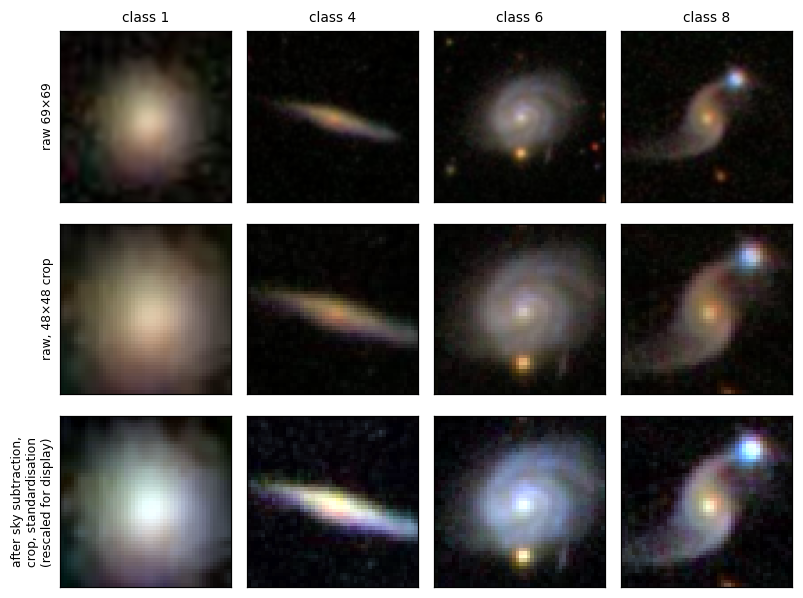

In [12]:
Ptr = pre.transform(Xtr); Pva = pre.transform(Xva)
print("processed training set: mean per band", np.round(Ptr.mean(axis=(0, 2, 3), dtype=np.float64), 4), " std per band", np.round(Ptr.std(axis=(0, 2, 3), dtype=np.float64), 4))
print("processed validation set: mean per band", np.round(Pva.mean(axis=(0, 2, 3), dtype=np.float64), 3), " std per band", np.round(Pva.std(axis=(0, 2, 3), dtype=np.float64), 3))

show = [int(np.where(y_tr == c)[0][0]) for c in (1, 4, 6, 8)]
fig, axes = plt.subplots(3, 4, figsize=(7.4, 5.6))
for j, i in enumerate(show):
    axes[0, j].imshow(Xtr[i]); axes[0, j].set_title(f"class {y_tr[i]}", fontsize=9)
    crop_raw = Xtr[i, 10:58, 10:58]
    axes[1, j].imshow(crop_raw);
    p = Ptr[i].transpose(1, 2, 0); lo, hi = np.percentile(p, [1, 99.5])
    axes[2, j].imshow(np.clip((p - lo) / (hi - lo), 0, 1))
for r_, t in enumerate(["raw 69×69", "raw, 48×48 crop", "after sky subtraction,\ncrop, standardisation\n(rescaled for display)"]):
    axes[r_, 0].set_ylabel(t, fontsize=8)
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_2_3_before_after.png", bbox_inches="tight"); plt.show()

In [13]:
cfg = dict(seed=SEED, keep_classes=KEEP, crop=CROP, subtract_sky=True, mean=pre.mean.tolist(), std=pre.std.tolist(),
           class_weights=class_weights.tolist(), n_train=len(idx_tr), n_val=len(idx_va), n_test=len(idx_te))
json.dump(cfg, open("preproc_config.json", "w"), indent=1)
print("saved splits.npz and preproc_config.json")

saved splits.npz and preproc_config.json


## Decisions used in the rest of the homework
* Classes: class 5 (edge-on, boxy bulge; 17 images) dropped, nine classes, labels re-numbered 0–8 (`KEEP`, `label_map`).
* Split: stratified 70 / 15 / 15, seed 42 (`splits.npz`).
* Preprocessing: sky level (median of the outer frame, per band) subtracted → central 48×48 crop → standardisation with training-set mean and std per band (`preproc_config.json`).
* Imbalance: class-weighted cross-entropy with w_c = N / (K n_c); report balanced accuracy and macro-F1 besides accuracy.

# Part 3: FCNN vs. 2D CNN on equal footing
Protocol used for **every** run in this part: same training / validation / test sets and the same preprocessing as in Part 2 (no augmentation);
class-weighted cross-entropy (weights from 2.3d), Adam with learning rate 1e-3, batch size 128, at most 50 epochs;
early stopping on the validation loss with patience 5, restoring the best weights; the same hardware for all timings
(clock read after a device synchronisation). The test set is used only once per trained model, after training has finished.
The output layer has 9 units (nine classes), so the parameter counts are slightly below those of T1 (which used 10 outputs).

In [14]:
import time, subprocess
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.metrics import f1_score, roc_curve, auc

if torch.cuda.is_available():
    DEVICE = torch.device("cuda"); HW = torch.cuda.get_device_name(0); sync = torch.cuda.synchronize
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps"); sync = torch.mps.synchronize
    try:
        chip = subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip()
    except Exception:
        chip = "Apple silicon"
    HW = f"{chip} GPU (PyTorch MPS)"
else:
    DEVICE = torch.device("cpu"); HW = "CPU"; sync = lambda: None
print("hardware used for all timings:", HW, "| torch", torch.__version__)

K = 9
SEEDS = [0, 1, 2]
MODELS = ["CNN", "FCNN-matched", "FCNN-large"]
COL = {"CNN": "tab:blue", "FCNN-matched": "tab:orange", "FCNN-large": "tab:green"}

Xte = images[idx_te]
Pte = pre.transform(Xte)          # test inputs: used only for the final evaluation of trained models
def to_dev(a): return torch.from_numpy(np.ascontiguousarray(a)).to(DEVICE)
Xtr_t, Xva_t, Xte_t = to_dev(Ptr), to_dev(Pva), to_dev(Pte)
ytr_t, yva_t, yte_t = (torch.from_numpy(v).long().to(DEVICE) for v in (y_tr, y_va, y_te))
W = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)
print("inputs:", tuple(Xtr_t.shape), tuple(Xva_t.shape), tuple(Xte_t.shape), "| class weights:", np.round(class_weights, 2))

hardware used for all timings: Apple M5 GPU (PyTorch MPS) | torch 2.8.0


inputs: (15237, 3, 48, 48) (3265, 3, 48, 48) (3266, 3, 48, 48) | class weights: [0.7  0.35 0.38 6.94 1.58 4.11 2.16 2.67 4.66]


## 3.1 Baseline comparison
### The three reference models and their parameter counts

In [15]:
def make_model(name, n_out=K):
    if name == "CNN":
        return nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(6 * 6 * 64, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, n_out))
    if name == "FCNN-matched":
        return nn.Sequential(nn.Flatten(), nn.Linear(6912, 24), nn.ReLU(),
                             nn.Linear(24, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, n_out))
    if name == "FCNN-large":
        return nn.Sequential(nn.Flatten(), nn.Linear(6912, 256), nn.ReLU(),
                             nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, n_out))
    raise ValueError(name)

def n_params(m): return sum(p.numel() for p in m.parameters())

T1_ANSWER = {"CNN": 171754, "FCNN-matched": 168162, "FCNN-large": 1803914}     # my answer to T1 (10 outputs)
print(f"{'model':<14}{'T1 answer (10 outputs)':>24}{'PyTorch (10 outputs)':>22}{'used here (9 outputs)':>23}")
PARAMS = {}
for name in MODELS:
    p10, p9 = n_params(make_model(name, 10)), n_params(make_model(name, K))
    assert p10 == T1_ANSWER[name], (name, p10)
    PARAMS[name] = p9
    print(f"{name:<14}{T1_ANSWER[name]:>24,}{p10:>22,}{p9:>23,}")

model           T1 answer (10 outputs)  PyTorch (10 outputs)  used here (9 outputs)
CNN                            171,754               171,754                171,689
FCNN-matched                   168,162               168,162                168,097
FCNN-large                   1,803,914             1,803,914              1,803,785


### Training and evaluation code

In [16]:
def evaluate(model, X, y, bs=1024):
    """weighted cross-entropy over the whole set (same loss as in training) and the predicted labels"""
    model.eval(); tot = torch.zeros((), device=DEVICE); wsum = torch.zeros((), device=DEVICE); preds = []
    with torch.no_grad():
        for a in range(0, len(X), bs):
            out = model(X[a:a + bs]); yy = y[a:a + bs]
            tot += F.cross_entropy(out, yy, weight=W, reduction="sum"); wsum += W[yy].sum()
            preds.append(out.argmax(1))
    return (tot / wsum).item(), torch.cat(preds).cpu().numpy()

def predict_proba(model, X, bs=1024):
    model.eval(); out = []
    with torch.no_grad():
        for a in range(0, len(X), bs):
            out.append(F.softmax(model(X[a:a + bs]), dim=1))
    return torch.cat(out).cpu().numpy()

def balanced_acc(y, p):
    cm = np.bincount(y * K + p, minlength=K * K).reshape(K, K)
    return float(np.mean(np.diag(cm) / np.maximum(cm.sum(1), 1)))

def train_run(name, seed, Xt, Xv, max_epochs=50, patience=5):
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_model(name).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    g = torch.Generator(); g.manual_seed(seed)
    hist = dict(train_loss=[], val_loss=[], val_acc=[], val_bal=[], epoch_time=[])
    best_loss, best_epoch, best_state, bad = float("inf"), 0, None, 0
    yv = yva_t.cpu().numpy()
    for ep in range(1, max_epochs + 1):
        sync(); t0 = time.perf_counter()
        model.train(); perm = torch.randperm(len(Xt), generator=g).to(DEVICE)
        tl = torch.zeros((), device=DEVICE); tw = torch.zeros((), device=DEVICE)
        for a in range(0, len(Xt), 128):
            idx = perm[a:a + 128]; xb, yb = Xt[idx], ytr_t[idx]
            out = model(xb); loss = F.cross_entropy(out, yb, weight=W)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
            tl += F.cross_entropy(out.detach(), yb, weight=W, reduction="sum"); tw += W[yb].sum()
        vl, vp = evaluate(model, Xv, yva_t)          # predictions are copied to the CPU here, which also synchronises
        sync(); t1 = time.perf_counter()
        hist["train_loss"].append((tl / tw).item()); hist["val_loss"].append(vl)
        hist["val_acc"].append(float(np.mean(vp == yv))); hist["val_bal"].append(balanced_acc(yv, vp))
        hist["epoch_time"].append(t1 - t0)           # one epoch = training pass + validation pass
        if vl < best_loss:
            best_loss, best_epoch, bad = vl, ep, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state)                # restore the best weights
    return model, hist, best_epoch

def final_eval(model, Xt_, yt_np):
    _, p = evaluate(model, Xt_, torch.from_numpy(yt_np).long().to(DEVICE))
    return dict(test_acc=float(np.mean(p == yt_np)), test_bal=balanced_acc(yt_np, p),
                test_f1=float(f1_score(yt_np, p, average="macro")), pred=p)

### Training: 3 models × 3 seeds

In [17]:
runs = {}
t_start = time.time()
for name in MODELS:
    for seed in SEEDS:
        model, hist, best_ep = train_run(name, seed, Xtr_t, Xva_t)
        r = dict(model=model, hist=hist, best_epoch=best_ep, epochs_run=len(hist["val_loss"]),
                 val_acc_best=hist["val_acc"][best_ep - 1], val_bal_best=hist["val_bal"][best_ep - 1])
        r.update(final_eval(model, Xte_t, y_te)); r["proba"] = predict_proba(model, Xte_t)
        runs[(name, seed)] = r
        print(f"{name:<13} seed {seed}: {r['epochs_run']:>2} epochs run, best epoch {best_ep:>2}, "
              f"{np.mean(hist['epoch_time']):.2f} s/epoch | val acc {r['val_acc_best']:.3f} | test acc {r['test_acc']:.3f}, balanced {r['test_bal']:.3f}")
print(f"total training time: {(time.time() - t_start) / 60:.1f} min")

CNN           seed 0: 23 epochs run, best epoch 18, 0.87 s/epoch | val acc 0.704 | test acc 0.703, balanced 0.671


CNN           seed 1: 22 epochs run, best epoch 17, 0.85 s/epoch | val acc 0.676 | test acc 0.664, balanced 0.656


CNN           seed 2: 25 epochs run, best epoch 20, 0.85 s/epoch | val acc 0.684 | test acc 0.688, balanced 0.662


FCNN-matched  seed 0: 20 epochs run, best epoch 15, 0.11 s/epoch | val acc 0.635 | test acc 0.636, balanced 0.573


FCNN-matched  seed 1: 18 epochs run, best epoch 13, 0.10 s/epoch | val acc 0.568 | test acc 0.579, balanced 0.563


FCNN-matched  seed 2: 22 epochs run, best epoch 17, 0.10 s/epoch | val acc 0.672 | test acc 0.679, balanced 0.584


FCNN-large    seed 0: 20 epochs run, best epoch 15, 0.20 s/epoch | val acc 0.633 | test acc 0.635, balanced 0.599


FCNN-large    seed 1: 22 epochs run, best epoch 17, 0.20 s/epoch | val acc 0.678 | test acc 0.683, balanced 0.625


FCNN-large    seed 2: 21 epochs run, best epoch 16, 0.20 s/epoch | val acc 0.686 | test acc 0.693, balanced 0.609
total training time: 1.3 min


### Results table (mean ± standard deviation over the 3 seeds)
Target for the time-to-accuracy columns: the best validation accuracy reached by FCNN-matched (highest over its three runs). Runs that never reach it are counted as 'not reached' (the number in brackets is how many of the 3 runs reached it).

In [18]:
def ms(v, f="{:.3f}"):
    v = np.asarray(v, float)
    return (f + " ± " + f).format(v.mean(), v.std()) if len(v) else "n/a"

TARGET = max(max(runs[("FCNN-matched", s)]["hist"]["val_acc"]) for s in SEEDS)      # best validation accuracy reached by FCNN-matched
print(f"target validation accuracy = {TARGET:.4f} (best validation accuracy reached by FCNN-matched)\n")
for r in runs.values():
    ok = [i for i, a in enumerate(r["hist"]["val_acc"]) if a >= TARGET]
    r["epochs_to_target"] = (ok[0] + 1) if ok else None
    r["time_to_target"] = float(np.sum(r["hist"]["epoch_time"][:ok[0] + 1])) if ok else None

hdr = f"{'model':<13}{'params':>10}  {'test acc':>14}  {'balanced acc':>14}  {'macro F1':>14}  {'s / epoch':>13}  {'epochs to target':>18}  {'time to target (s)':>19}  {'best epoch':>12}"
print(hdr)
for name in MODELS:
    R = [runs[(name, s)] for s in SEEDS]
    e2t = [r["epochs_to_target"] for r in R if r["epochs_to_target"] is not None]
    t2t = [r["time_to_target"] for r in R if r["time_to_target"] is not None]
    print(f"{name:<13}{PARAMS[name]:>10,}  {ms([r['test_acc'] for r in R]):>14}  {ms([r['test_bal'] for r in R]):>14}  {ms([r['test_f1'] for r in R]):>14}  "
          f"{ms([np.mean(r['hist']['epoch_time']) for r in R], '{:.2f}'):>13}  {ms(e2t, '{:.1f}') + ' (' + str(len(e2t)) + '/3)':>18}  "
          f"{ms(t2t, '{:.1f}') + ' (' + str(len(t2t)) + '/3)':>19}  {ms([r['best_epoch'] for r in R], '{:.1f}'):>12}")
print("\nper run (seed 0, 1, 2) epochs to target:", {n: [runs[(n, s)]["epochs_to_target"] for s in SEEDS] for n in MODELS})
print("per run (seed 0, 1, 2) seconds to target:", {n: [None if runs[(n, s)]["time_to_target"] is None else round(runs[(n, s)]["time_to_target"], 2) for s in SEEDS] for n in MODELS})
print("\nepochs run before stopping:", {n: [runs[(n, s)]['epochs_run'] for s in SEEDS] for n in MODELS})

target validation accuracy = 0.6720 (best validation accuracy reached by FCNN-matched)

model            params        test acc    balanced acc        macro F1      s / epoch    epochs to target   time to target (s)    best epoch
CNN             171,689   0.685 ± 0.016   0.663 ± 0.006   0.602 ± 0.005    0.86 ± 0.01    13.3 ± 4.6 (3/3)     11.5 ± 3.8 (3/3)    18.3 ± 1.2
FCNN-matched    168,097   0.631 ± 0.041   0.573 ± 0.008   0.514 ± 0.018    0.10 ± 0.00    17.0 ± 0.0 (1/3)      1.7 ± 0.0 (1/3)    15.0 ± 1.6
FCNN-large    1,803,785   0.670 ± 0.025   0.611 ± 0.011   0.547 ± 0.019    0.20 ± 0.00    15.7 ± 3.3 (3/3)      3.1 ± 0.7 (3/3)    16.0 ± 0.8

per run (seed 0, 1, 2) epochs to target: {'CNN': [7, 15, 18], 'FCNN-matched': [None, None, 17], 'FCNN-large': [20, 15, 12]}
per run (seed 0, 1, 2) seconds to target: {'CNN': [6.27, 12.81, 15.36], 'FCNN-matched': [None, None, 1.71], 'FCNN-large': [4.0, 2.96, 2.38]}

epochs run before stopping: {'CNN': [23, 22, 25], 'FCNN-matched': [20, 18, 22

### Loss curves

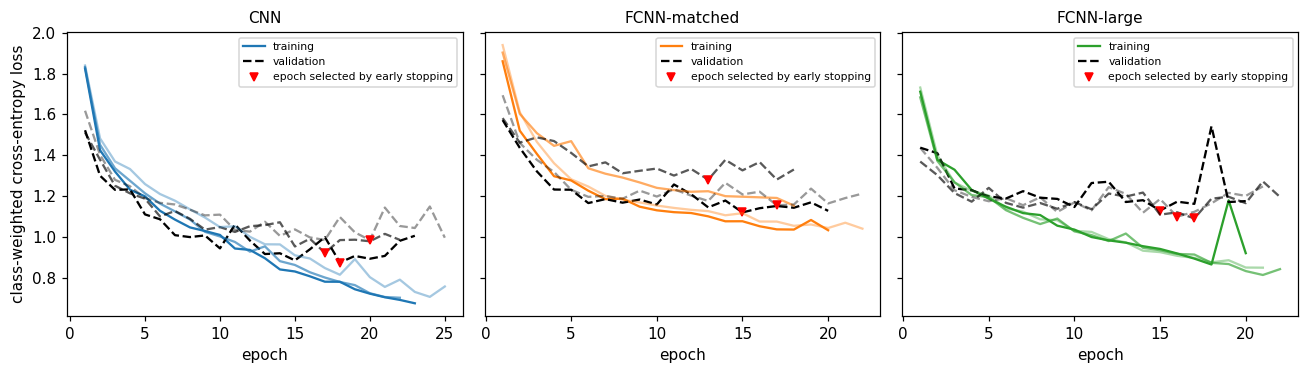

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, name in zip(axes, MODELS):
    for s, ls_alpha in zip(SEEDS, (1.0, 0.65, 0.4)):
        h = runs[(name, s)]["hist"]; ep = np.arange(1, len(h["val_loss"]) + 1)
        ax.plot(ep, h["train_loss"], color=COL[name], alpha=ls_alpha, label="training" if s == 0 else None)
        ax.plot(ep, h["val_loss"], "--", color="k", alpha=ls_alpha, label="validation" if s == 0 else None)
        ax.plot(runs[(name, s)]["best_epoch"], h["val_loss"][runs[(name, s)]["best_epoch"] - 1], "v", color="r", ms=5,
                label="epoch selected by early stopping" if s == 0 else None)
    ax.set_title(name, fontsize=10); ax.set_xlabel("epoch"); ax.legend(fontsize=7)
axes[0].set_ylabel("class-weighted cross-entropy loss")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_3_1_curves.png", bbox_inches="tight"); plt.show()

### Confusion matrices (best seed of each model, chosen with the validation balanced accuracy)

best seed per model (by validation balanced accuracy): {'CNN': 0, 'FCNN-matched': 0, 'FCNN-large': 1}


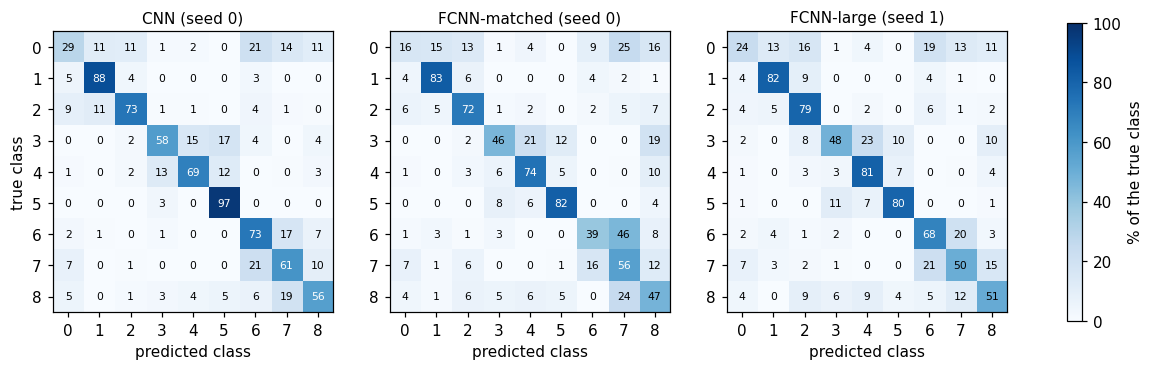


CNN: recall per class (%): [29. 88. 73. 58. 69. 97. 73. 61. 56.]
   largest confusions (true -> predicted, % of the true class): [('7->6', np.float64(21.3)), ('0->6', np.float64(20.8)), ('8->7', np.float64(19.2)), ('3->5', np.float64(17.3)), ('6->7', np.float64(16.7)), ('3->4', np.float64(15.4))]

FCNN-matched: recall per class (%): [16. 83. 72. 46. 74. 82. 39. 56. 47.]
   largest confusions (true -> predicted, % of the true class): [('6->7', np.float64(45.8)), ('0->7', np.float64(24.7)), ('8->7', np.float64(24.4)), ('3->4', np.float64(21.2)), ('3->8', np.float64(19.2)), ('0->8', np.float64(16.2))]

FCNN-large: recall per class (%): [24. 82. 79. 48. 81. 80. 68. 50. 51.]
   largest confusions (true -> predicted, % of the true class): [('3->4', np.float64(23.1)), ('7->6', np.float64(21.3)), ('6->7', np.float64(20.2)), ('0->6', np.float64(19.3)), ('0->2', np.float64(16.0)), ('7->8', np.float64(15.4))]


In [20]:
best_seed = {n: max(SEEDS, key=lambda s: runs[(n, s)]["val_bal_best"]) for n in MODELS}
print("best seed per model (by validation balanced accuracy):", best_seed)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, name in zip(axes, MODELS):
    p = runs[(name, best_seed[name])]["pred"]
    cm = np.bincount(y_te * K + p, minlength=K * K).reshape(K, K)
    cmn = 100 * cm / cm.sum(1, keepdims=True)
    im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=100)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, f"{cmn[i, j]:.0f}", ha="center", va="center", fontsize=7, color="w" if cmn[i, j] > 55 else "k")
    ax.set_xticks(range(K)); ax.set_yticks(range(K))
    ax.set_xlabel("predicted class"); ax.set_title(f"{name} (seed {best_seed[name]})", fontsize=10)
axes[0].set_ylabel("true class")
fig.colorbar(im, ax=axes, shrink=0.8, label="% of the true class")
plt.savefig(f"{FIG_DIR}/fig_3_1_confusion.png", bbox_inches="tight"); plt.show()

for name in MODELS:
    p = runs[(name, best_seed[name])]["pred"]
    cm = np.bincount(y_te * K + p, minlength=K * K).reshape(K, K)
    rec = np.diag(cm) / cm.sum(1)
    off = [(100 * cm[i, j] / cm[i].sum(), i, j) for i in range(K) for j in range(K) if i != j]
    off.sort(reverse=True)
    print(f"\n{name}: recall per class (%):", np.round(100 * rec, 0))
    print("   largest confusions (true -> predicted, % of the true class):", [(f"{i}->{j}", round(v, 1)) for v, i, j in off[:6]])

### One-vs-rest ROC curves for two classes (3 = cigar shaped, 7 = medium spiral)

class 3 (cigar) vs rest, CNN (seed 0): AUC = 0.965
class 3 (cigar) vs rest, FCNN-matched (seed 0): AUC = 0.964
class 3 (cigar) vs rest, FCNN-large (seed 1): AUC = 0.969
class 7 (medium spiral) vs rest, CNN (seed 0): AUC = 0.952
class 7 (medium spiral) vs rest, FCNN-matched (seed 0): AUC = 0.895
class 7 (medium spiral) vs rest, FCNN-large (seed 1): AUC = 0.917


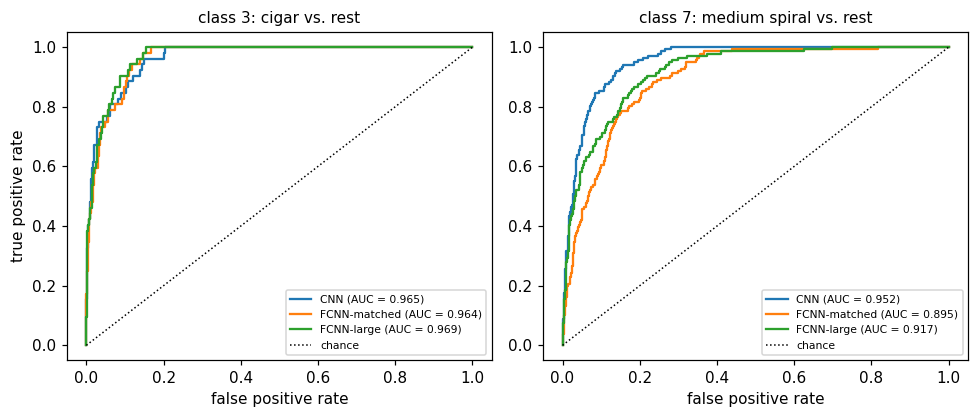

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.9))
for ax, c in zip(axes, (3, 7)):
    for name in MODELS:
        pr = runs[(name, best_seed[name])]["proba"][:, c]
        fpr, tpr, _ = roc_curve((y_te == c).astype(int), pr)
        ax.plot(fpr, tpr, color=COL[name], label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
        print(f"class {c} ({SHORT[c].replace(chr(10), ' ')}) vs rest, {name} (seed {best_seed[name]}): AUC = {auc(fpr, tpr):.3f}")
    ax.plot([0, 1], [0, 1], "k:", lw=1, label="chance")
    ax.set_xlabel("false positive rate"); ax.set_title(f"class {c}: {SHORT[c].replace(chr(10), ' ')} vs. rest", fontsize=10)
    ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("true positive rate")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_3_1_roc.png", bbox_inches="tight"); plt.show()

## 3.2 Shifted galaxies
The 48×48 window is moved by d pixels (random direction for each test image; the same directions are used for all models and all d) from the centre of the 69×69 cutout. The same sky subtraction and standardisation are used.

d (px)                       0               2               4               6               8
CNN              0.685 ± 0.016   0.651 ± 0.006   0.516 ± 0.010   0.375 ± 0.013   0.276 ± 0.024
FCNN-matched     0.631 ± 0.041   0.602 ± 0.043   0.436 ± 0.049   0.242 ± 0.040   0.149 ± 0.033
FCNN-large       0.670 ± 0.025   0.634 ± 0.035   0.432 ± 0.051   0.202 ± 0.035   0.130 ± 0.020


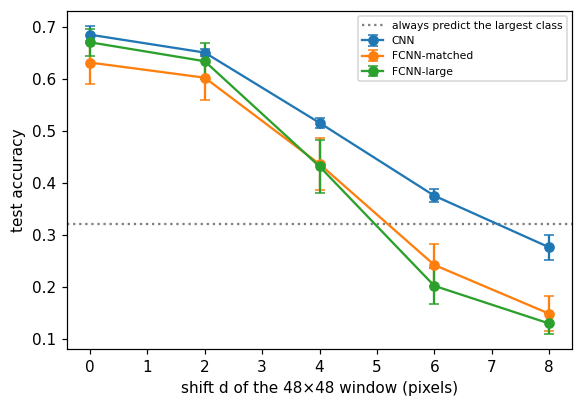

In [22]:
def shifted_inputs(Xraw, d, seed=SEED + 2):
    r = np.random.default_rng(seed); th = r.uniform(0, 2 * np.pi, len(Xraw))
    dy = np.rint(d * np.sin(th)).astype(int); dx = np.rint(d * np.cos(th)).astype(int)
    X = Xraw.astype(np.float32)
    X = X - np.median(X[:, frame, :], axis=1)[:, None, None, :]
    s0 = (69 - 48) // 2
    out = np.stack([X[i, s0 + dy[i]: s0 + dy[i] + 48, s0 + dx[i]: s0 + dx[i] + 48, :] for i in range(len(X))])
    return np.ascontiguousarray(((out - pre.mean) / pre.std).transpose(0, 3, 1, 2).astype(np.float32))

assert np.allclose(shifted_inputs(Xte, 0), Pte, atol=1e-4)          # d = 0 is the unshifted test set
SHIFTS = [0, 2, 4, 6, 8]
shift_acc = {n: np.zeros((len(SEEDS), len(SHIFTS))) for n in MODELS}
for k, d in enumerate(SHIFTS):
    Xs = to_dev(shifted_inputs(Xte, d))
    for name in MODELS:
        for i, s in enumerate(SEEDS):
            _, p = evaluate(runs[(name, s)]["model"], Xs, yte_t)
            shift_acc[name][i, k] = np.mean(p == y_te)
print(f"{'d (px)':<14}" + "".join(f"{d:>16}" for d in SHIFTS))
for name in MODELS:
    print(f"{name:<14}" + "".join(f"{ms(shift_acc[name][:, k]):>16}" for k in range(len(SHIFTS))))

fig, ax = plt.subplots(figsize=(5.4, 3.8))
for name in MODELS:
    ax.errorbar(SHIFTS, shift_acc[name].mean(0), yerr=shift_acc[name].std(0), marker="o", capsize=3, color=COL[name], label=name)
ax.axhline(np.mean(y_te == np.bincount(y_tr).argmax()), color="gray", ls=":", label="always predict the largest class")
ax.set_xlabel("shift d of the 48×48 window (pixels)"); ax.set_ylabel("test accuracy"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_3_2_shift.png", bbox_inches="tight"); plt.show()

## 3.3 Scrambled pixels
One random permutation of the 48×48 pixel positions (the same for the three bands) is applied to every training, validation and test image; CNN and FCNN-matched are retrained from scratch with the same protocol.

scrambled CNN           seed 0: 20 epochs run, best epoch 15 | test acc 0.646, balanced 0.612


scrambled CNN           seed 1: 22 epochs run, best epoch 17 | test acc 0.675, balanced 0.608


scrambled CNN           seed 2: 24 epochs run, best epoch 19 | test acc 0.706, balanced 0.630


scrambled FCNN-matched  seed 0: 20 epochs run, best epoch 15 | test acc 0.647, balanced 0.574


scrambled FCNN-matched  seed 1: 22 epochs run, best epoch 17 | test acc 0.640, balanced 0.570


scrambled FCNN-matched  seed 2: 13 epochs run, best epoch  8 | test acc 0.612, balanced 0.559

model            test acc (original)   test acc (scrambled)   balanced acc (original)   balanced acc (scrambled)
CNN                    0.685 ± 0.016          0.675 ± 0.025             0.663 ± 0.006              0.617 ± 0.010
FCNN-matched           0.631 ± 0.041          0.633 ± 0.015             0.573 ± 0.008              0.568 ± 0.006


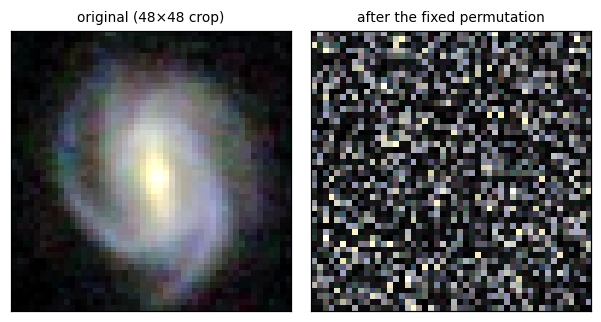

In [23]:
perm_pix = np.random.default_rng(SEED + 1).permutation(48 * 48)
def scramble(P): return P.reshape(len(P), 3, -1)[:, :, perm_pix].reshape(P.shape)
Str_t, Sva_t, Ste_t = (to_dev(scramble(a)) for a in (Ptr, Pva, Pte))

scr = {}
for name in ("CNN", "FCNN-matched"):
    for seed in SEEDS:
        model, hist, best_ep = train_run(name, seed, Str_t, Sva_t)
        r = dict(hist=hist, best_epoch=best_ep, epochs_run=len(hist["val_loss"])); r.update(final_eval(model, Ste_t, y_te))
        scr[(name, seed)] = r
        print(f"scrambled {name:<13} seed {seed}: {r['epochs_run']:>2} epochs run, best epoch {best_ep:>2} | test acc {r['test_acc']:.3f}, balanced {r['test_bal']:.3f}")

print(f"\n{'model':<14}{'test acc (original)':>22}{'test acc (scrambled)':>23}{'balanced acc (original)':>26}{'balanced acc (scrambled)':>27}")
for name in ("CNN", "FCNN-matched"):
    print(f"{name:<14}{ms([runs[(name, s)]['test_acc'] for s in SEEDS]):>22}{ms([scr[(name, s)]['test_acc'] for s in SEEDS]):>23}"
          f"{ms([runs[(name, s)]['test_bal'] for s in SEEDS]):>26}{ms([scr[(name, s)]['test_bal'] for s in SEEDS]):>27}")

i0 = int(np.where(y_te == 7)[0][0])
def disp(p):
    q = p.transpose(1, 2, 0); lo, hi = np.percentile(q, [1, 99.5]); return np.clip((q - lo) / (hi - lo), 0, 1)
fig, axes = plt.subplots(1, 2, figsize=(5.6, 2.9))
axes[0].imshow(disp(Pte[i0])); axes[0].set_title("original (48×48 crop)", fontsize=9)
axes[1].imshow(disp(scramble(Pte[i0:i0 + 1])[0])); axes[1].set_title("after the fixed permutation", fontsize=9)
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_3_3_scrambled.png", bbox_inches="tight"); plt.show()

## Optional extension B2: robustness to noise
Gaussian noise with standard deviation k·σ_sky (σ_sky per image and band, as in Part 2, estimated from the outer frame of the test image itself)
is added to the **raw** test images, before the normalisation, and the result is clipped to the valid pixel range 0–255. The models of 3.1 are evaluated without retraining.
The same random numbers are used for all k and all models (only their scale k·σ_sky changes).

median sigma_sky of the test images (g, r, i): [4.45 2.97 2.97] counts

test accuracy            k = 0           k = 1           k = 2           k = 4
CNN              0.685 ± 0.016   0.676 ± 0.018   0.646 ± 0.020   0.539 ± 0.025
FCNN-matched     0.631 ± 0.041   0.628 ± 0.042   0.628 ± 0.044   0.628 ± 0.045
FCNN-large       0.670 ± 0.025   0.669 ± 0.026   0.670 ± 0.027   0.671 ± 0.019

balanced acc.            k = 0           k = 1           k = 2           k = 4
CNN              0.663 ± 0.006   0.654 ± 0.009   0.637 ± 0.009   0.576 ± 0.021
FCNN-matched     0.573 ± 0.008   0.570 ± 0.008   0.568 ± 0.012   0.566 ± 0.015
FCNN-large       0.611 ± 0.011   0.610 ± 0.012   0.613 ± 0.012   0.602 ± 0.013


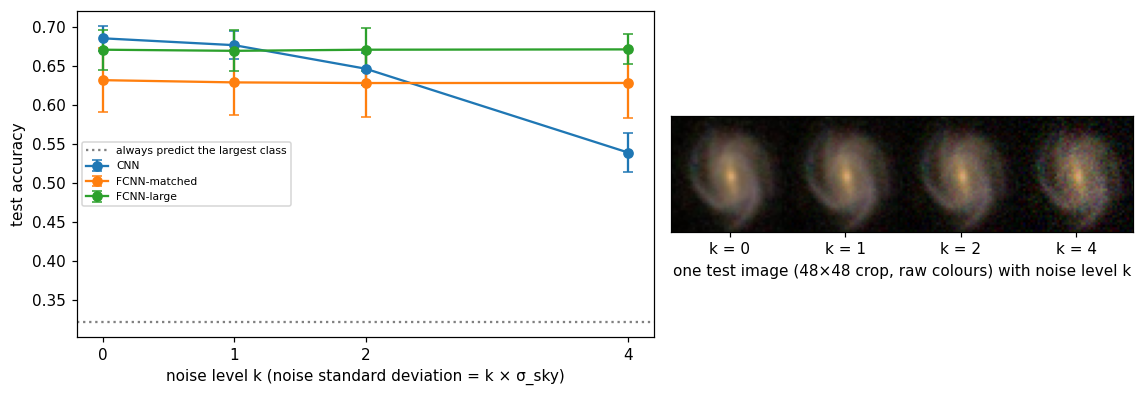

In [24]:
Bt = Xte[:, frame, :].astype(np.float32)
sky_med_te = np.median(Bt, axis=1)
sigma_te = np.maximum(1.4826 * np.median(np.abs(Bt - sky_med_te[:, None, :]), axis=1), 1.4826)     # same estimator and floor as in Part 2
del Bt
K_LIST = [0, 1, 2, 4]
z = np.random.default_rng(SEED + 3).standard_normal(Xte.shape).astype(np.float32)
noise_acc = {n: np.zeros((len(SEEDS), len(K_LIST))) for n in MODELS}
noise_bal = {n: np.zeros((len(SEEDS), len(K_LIST))) for n in MODELS}
noisy_example = {}
for a, k in enumerate(K_LIST):
    Xn = np.clip(Xte.astype(np.float32) + z * (k * sigma_te)[:, None, None, :], 0, 255)
    noisy_example[k] = Xn[i0]
    Pn = to_dev(pre.transform(Xn))
    for name in MODELS:
        for i, s in enumerate(SEEDS):
            _, p = evaluate(runs[(name, s)]["model"], Pn, yte_t)
            noise_acc[name][i, a] = np.mean(p == y_te); noise_bal[name][i, a] = balanced_acc(y_te, p)
for name in MODELS:                                           # k = 0 must reproduce the baseline of 3.1
    assert np.allclose(noise_acc[name][:, 0], [runs[(name, s)]["test_acc"] for s in SEEDS])
print("median sigma_sky of the test images (g, r, i):", np.round(np.median(sigma_te, axis=0), 2), "counts")
print(f"\n{'test accuracy':<14}" + "".join(f"{'k = ' + str(k):>16}" for k in K_LIST))
for name in MODELS:
    print(f"{name:<14}" + "".join(f"{ms(noise_acc[name][:, a]):>16}" for a in range(len(K_LIST))))
print(f"\n{'balanced acc.':<14}" + "".join(f"{'k = ' + str(k):>16}" for k in K_LIST))
for name in MODELS:
    print(f"{name:<14}" + "".join(f"{ms(noise_bal[name][:, a]):>16}" for a in range(len(K_LIST))))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7), gridspec_kw=dict(width_ratios=[1.25, 1]))
for name in MODELS:
    axes[0].errorbar(K_LIST, noise_acc[name].mean(0), yerr=noise_acc[name].std(0), marker="o", capsize=3, color=COL[name], label=name)
axes[0].axhline(np.mean(y_te == np.bincount(y_tr).argmax()), color="gray", ls=":", label="always predict the largest class")
axes[0].set_xticks(K_LIST); axes[0].set_xlabel("noise level k (noise standard deviation = k × σ_sky)"); axes[0].set_ylabel("test accuracy"); axes[0].legend(fontsize=7)
strip = np.concatenate([np.clip(noisy_example[k][10:58, 10:58] / 255.0, 0, 1) for k in K_LIST], axis=1)
axes[1].imshow(strip); axes[1].set_xticks([24 + 48 * a for a in range(len(K_LIST))]); axes[1].set_xticklabels([f"k = {k}" for k in K_LIST]); axes[1].set_yticks([])
axes[1].set_xlabel("one test image (48×48 crop, raw colours) with noise level k")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig_3_B2_noise.png", bbox_inches="tight"); plt.show()